# Part C - a first solution, and Part D - checking it

The features come from `features.py`, the same golden-template pipeline described in B.2: align each image onto a reference, compare it with the median of the clean images, and take two numbers from the difference map.

**How data leakage is avoided.** The split happens first. The reference image, the golden template, the scaler and the model are all built on the **development split only**. The validation images are used once, for the numbers in Part D. `test.csv` is only ever read to produce predictions - it never takes part in a fit, a threshold or a metric.


In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import (Aligner, align_images, build_template, difference_map,
                      features_from_diff, load_grey, standardise, FEATURE_NAMES)

DATA_DIR = Path(".")
SEED = 42
sns.set_theme(style="whitegrid")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "| test:", test.shape, "| features:", FEATURE_NAMES)


train: (168, 10) | test: (72, 8) | features: ['max_diff_norm', 'area_norm']


## C.2 Development / validation split

A stratified 70/30 split keeps the same defect rate in both halves. Everything that follows is fitted on `dev` only.


In [18]:
dev, val = train_test_split(train, test_size=0.3, stratify=train["inspector_label"],
                            random_state=SEED)
print(f"dev {len(dev):>3} images, {int(dev.inspector_label.sum())} defective "
      f"({dev.inspector_label.mean():.1%})")
print(f"val {len(val):>3} images, {int(val.inspector_label.sum())} defective "
      f"({val.inspector_label.mean():.1%})")


dev 117 images, 39 defective (33.3%)
val  51 images, 17 defective (33.3%)


### The golden template, built from development OK images only

The reference image and the template both come from `dev`. The validation and test images are aligned onto that same reference so that they are comparable, but they contribute nothing to it.


In [19]:
dev_ok = dev.loc[dev["inspector_label"] == 0, "file"].tolist()
reference_file = dev_ok[0]

aligner = Aligner(standardise(load_grey(reference_file, DATA_DIR)))
aligned, failures = align_images(list(train["file"]) + list(test["file"]),
                                 reference_file, DATA_DIR, aligner)
print(f"aligned {len(aligned) - len(failures)} / {len(aligned)} images; failures: {failures}")

template = build_template(aligned[f] for f in dev_ok)
print(f"golden template built from {len(dev_ok)} dev OK images")


def feature_frame(frame):
    """Attach the two template features to a dataframe of images."""
    rows = [features_from_diff(difference_map(aligned[f], template)) for f in frame["file"]]
    return pd.concat([frame.reset_index(drop=True), pd.DataFrame(rows)], axis=1)


dev_f, val_f, test_f = feature_frame(dev), feature_frame(val), feature_frame(test)
dev_f.groupby("inspector_label")[FEATURE_NAMES].median().round(1)


aligned 240 / 240 images; failures: []
golden template built from 78 dev OK images


,max_diff_norm,area_norm
inspector_label,,
0,6.4,4.0
1,35.3,531.0


## C.1 The model

A logistic regression on the two features, inside a pipeline with a scaler so both features reach it on the same scale. `class_weight="balanced"` compensates for the 2:1 imbalance between OK and defective images.


In [20]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
)
model.fit(dev_f[FEATURE_NAMES], dev_f["inspector_label"])

print("coefficients:", dict(zip(FEATURE_NAMES, model[-1].coef_[0].round(3))))

dev_score = model.predict_proba(dev_f[FEATURE_NAMES])[:, 1]
val_score = model.predict_proba(val_f[FEATURE_NAMES])[:, 1]
val_pred = (val_score >= 0.5).astype(int)

print("dev AUC:", round(roc_auc_score(dev_f["inspector_label"], dev_score), 3),
      "| val AUC:", round(roc_auc_score(val_f["inspector_label"], val_score), 3))


coefficients: {'max_diff_norm': np.float64(1.798), 'area_norm': np.float64(-0.386)}
dev AUC: 0.869 | val AUC: 0.919


`max_diff_norm` gets a large positive weight: a strong local difference means a defect. `area_norm` gets a small **negative** weight - a difference spread over a wide area is usually alignment noise rather than a defect, so the model uses it to damp those cases.

## D.1 Validation results

Confusion matrix, precision and recall - on the validation split only.


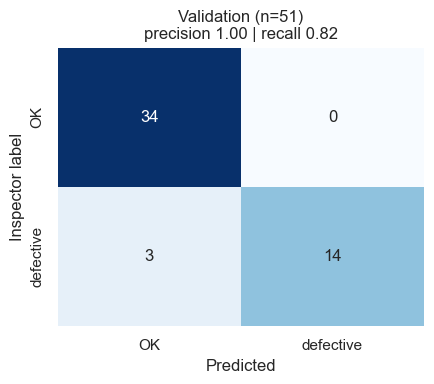

              precision    recall  f1-score   support

          OK       0.92      1.00      0.96        34
   defective       1.00      0.82      0.90        17

    accuracy                           0.94        51
   macro avg       0.96      0.91      0.93        51
weighted avg       0.95      0.94      0.94        51



In [21]:
cm = confusion_matrix(val_f["inspector_label"], val_pred)
precision = precision_score(val_f["inspector_label"], val_pred)
recall = recall_score(val_f["inspector_label"], val_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["OK", "defective"], yticklabels=["OK", "defective"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Inspector label")
ax.set_title(f"Validation (n={len(val_f)})\nprecision {precision:.2f} | recall {recall:.2f}")
plt.tight_layout()
plt.show()

print(classification_report(val_f["inspector_label"], val_pred,
                            target_names=["OK", "defective"]))


## D.2 One image the solution got wrong

I list the validation errors and take the one the model was least sure about - the score closest to 0.5.


In [22]:
val_f = val_f.assign(score=val_score, predicted=val_pred)
errors = val_f[val_f["predicted"] != val_f["inspector_label"]].copy()
errors["uncertainty"] = (errors["score"] - 0.5).abs()
errors = errors.sort_values("uncertainty")

errors[["image_id", "inspector_label", "inspector_type", "predicted", "score"]
       + FEATURE_NAMES + ["camera", "exposure_setting"]].round(2)


,image_id,inspector_label,inspector_type,predicted,score,max_diff_norm,area_norm,camera,exposure_setting
49,IMG_0111,1,stain,0,0.31,15.48,2341,CAM-B,LOW
40,IMG_0039,1,stain,0,0.25,6.76,13,CAM-A,NORMAL
8,IMG_0025,1,stain,0,0.21,4.63,0,CAM-B,AUTO


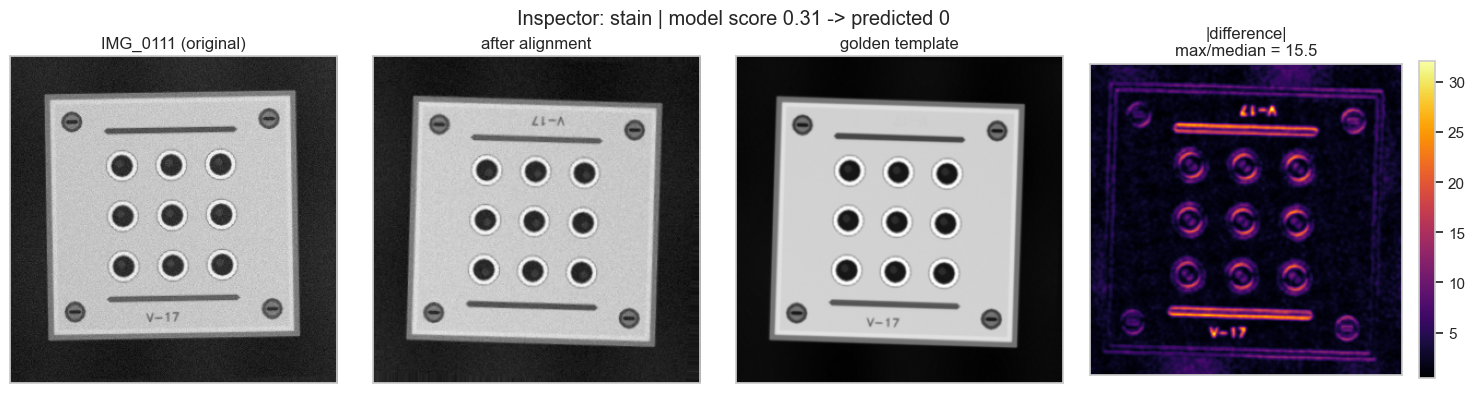

In [23]:
case = errors.iloc[0]
diff = difference_map(aligned[case["file"]], template)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(load_grey(case["file"], DATA_DIR), cmap="gray")
axes[0].set_title(f"{case['image_id']} (original)")
axes[1].imshow(aligned[case["file"]], cmap="gray")
axes[1].set_title("after alignment")
axes[2].imshow(template, cmap="gray")
axes[2].set_title("golden template")
im = axes[3].imshow(diff, cmap="inferno")
axes[3].set_title(f"|difference|\nmax/median = {case['max_diff_norm']:.1f}")
fig.colorbar(im, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Inspector: {case['inspector_type']} | model score {case['score']:.2f} "
             f"-> predicted {int(case['predicted'])}")
plt.tight_layout()
plt.show()


**Why the model missed it.**
The alignment step accidentally rotated the component by 180 degrees (notice the upside-down V-17 label in the "after alignment" image). Because the image was flipped, the difference map spread errors across the entire board, which caused the model's negative weight on area_norm to pull the defect score down to 0.31 (below the 0.5 threshold).

## C.3 Predictions for `test.csv`

The same template, the same scaler, the same model - applied to the 72 test images. `score` is the model's probability for the defective class.


In [24]:
test_score = model.predict_proba(test_f[FEATURE_NAMES])[:, 1]
predictions = pd.DataFrame({
    "image_id": test_f["image_id"],
    "predicted_defect": (test_score >= 0.5).astype(int),
    "score": test_score.round(4),
})

assert len(predictions) == 72, f"expected 72 rows, got {len(predictions)}"
assert list(predictions.columns) == ["image_id", "predicted_defect", "score"]
assert set(predictions["image_id"]) == set(test["image_id"]), "image_id mismatch with test.csv"
assert predictions["predicted_defect"].isin([0, 1]).all()
assert predictions["score"].between(0, 1).all()
assert predictions.notna().all().all()
assert (predictions["predicted_defect"] == (predictions["score"] >= 0.5).astype(int)).all()

predictions.to_csv(DATA_DIR / "predictions.csv", index=False)
print(f"wrote predictions.csv: {len(predictions)} rows, "
      f"{int(predictions.predicted_defect.sum())} flagged "
      f"({predictions.predicted_defect.mean():.1%}); "
      f"train defect rate {train.inspector_label.mean():.1%}")
predictions.head()


wrote predictions.csv: 72 rows, 18 flagged (25.0%); train defect rate 33.3%


,image_id,predicted_defect,score
0,IMG_0001,0,0.1284
1,IMG_0002,0,0.2646
2,IMG_0003,0,0.3010
3,IMG_0010,0,0.3247
4,IMG_0014,1,0.9989
